# PnP validation

Checks the geometry half of the keypoint pipeline without a trained network: the 3D keypoint model, `solve_pose`, and the heatmap decoder. Sections 1-6 give PnP keypoints projected from ground-truth poses, sometimes with added noise or outliers, so any error there comes from the solver rather than a detector. Section 7 runs the trained detector, and section 8 uses the regression model as a prior when decoding its heatmaps.

1. Keypoint model vs. dataset labels
2. Exact round trip
3. Sensitivity to keypoint noise
4. Annotated estimates
5. Outlier rejection
6. Best case through the heatmap decoder
7. Trained checkpoint
8. Regression prior

## Commands

```bash
# project the keypoint model onto a few labeled frames (writes PNGs)
uv run python scripts/sanity_check_keypoints.py --data-root data/speedplusv2 \
    --indices 0 12000 25630 --output-dir keypoint_checks

# train the keypoint model: writes checkpoints/keypoint/{best,last}.pt and metrics.csv
uv run python -m tumbleweed.train_keypoints --data-root data/speedplusv2 --epochs 12 --device mps

# evaluate with the same SPEC metrics as the regression baseline
uv run python -m tumbleweed.eval --model keypoint \
    --checkpoint checkpoints/keypoint/best.pt --device mps --advanced

# same, decoding with the regression model as a prior (section 8)
uv run python -m tumbleweed.eval --model keypoint \
    --checkpoint checkpoints/keypoint/best.pt --prior-checkpoint checkpoints/best.pt \
    --device mps --advanced --error-csv results/keypoint_prior_gated_val.csv
```

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import to_rgb

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from tumbleweed.data.camera import load_camera
from tumbleweed.geometry.pnp import solve_pose
from tumbleweed.geometry.projection import project_points
from tumbleweed.geometry.quaternion import geodesic_angle
from tumbleweed.geometry.tango_keypoints import BODY_EDGES, TANGO_KEYPOINTS_BODY

BLUE, ORANGE, GREEN = "tab:blue", "tab:orange", "tab:green"

plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

In [2]:
DATA_ROOT = REPO_ROOT / "data" / "speedplusv2"
DOMAIN, SPLIT = "synthetic", "train"

# frames to annotate (varied range and attitude)
SAMPLE_INDICES = [12000, 13852, 25630, 0]

NOISE_LEVELS_PX = [0.0, 1.0, 2.0, 4.0, 8.0]  # std-dev of Gaussian keypoint noise
N_STAT_SAMPLES = 300   # frames for the round-trip / noise statistics
N_TRIALS = 12          # noise draws per frame
SEED = 0

KEYPOINT_CHECKPOINT = REPO_ROOT / "checkpoints" / "keypoint" / "best.pt"
REGRESSION_CHECKPOINT = REPO_ROOT / "checkpoints" / "best.pt"
RESULTS_DIR = REPO_ROOT / "results"  # per-sample CSVs from tumbleweed.eval

# regression baseline on synthetic/validation (see regression_baseline.ipynb)
BASELINE_ROT_MEAN_DEG = 17.9
BASELINE_ROT_MEDIAN_DEG = 11.6
BASELINE_SPEC = 0.354

camera = load_camera(DATA_ROOT / "camera.json")
entries = json.load(open(DATA_ROOT / DOMAIN / f"{SPLIT}.json"))
rng = np.random.default_rng(SEED)

print(f"{len(entries)} labeled frames | image {camera.width}x{camera.height} "
      f"| fx={camera.fx:.1f} | {len(TANGO_KEYPOINTS_BODY)} keypoints")

47966 labeled frames | image 1920x1200 | fx=2988.6 | 11 keypoints


In [3]:
def pose_of(index):
    """Ground-truth (quaternion, translation) for a label index."""
    entry = entries[index]
    return (
        np.asarray(entry["q_vbs2tango_true"], dtype=np.float64),
        np.asarray(entry["r_Vo2To_vbs_true"], dtype=np.float64),
    )


def load_image(index):
    path = DATA_ROOT / DOMAIN / "images" / entries[index]["filename"]
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    return image


def rotation_error_deg(q_a, q_b):
    angle = geodesic_angle(
        torch.as_tensor(q_a, dtype=torch.float64)[None],
        torch.as_tensor(q_b, dtype=torch.float64)[None],
    )
    return float(np.rad2deg(angle.item()))


def translation_error(t_a, t_b):
    return float(np.linalg.norm(t_a - t_b) / np.linalg.norm(t_b))


def to_bgr(color):
    r, g, b = (int(round(255 * x)) for x in to_rgb(color))
    return (b, g, r)


def draw_wireframe(image, points_2d, color, dashed=False, thickness=2, label_points=False):
    """Draw the body box + antenna markers for a projected keypoint set."""
    bgr = to_bgr(color)
    for a, b in BODY_EDGES:
        p1 = tuple(np.round(points_2d[a]).astype(int))
        p2 = tuple(np.round(points_2d[b]).astype(int))
        if dashed:
            _dashed_segment(image, p1, p2, bgr, thickness)
        else:
            cv2.line(image, p1, p2, bgr, thickness, cv2.LINE_AA)
    for i, (u, v) in enumerate(points_2d):
        center = (int(round(u)), int(round(v)))
        radius = 9 if i >= 8 else 6
        cv2.circle(image, center, radius, bgr, thickness, cv2.LINE_AA)
        if label_points:
            cv2.putText(image, str(i), (center[0] + 11, center[1] - 11),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, bgr, 2, cv2.LINE_AA)
    return image


def _dashed_segment(image, p1, p2, bgr, thickness, dash=14.0, gap=9.0):
    start, end = np.asarray(p1, float), np.asarray(p2, float)
    length = float(np.linalg.norm(end - start))
    if length < 1e-6:
        return
    direction = (end - start) / length
    offset = 0.0
    while offset < length:
        tip = min(offset + dash, length)
        cv2.line(image,
                 tuple((start + direction * offset).astype(int)),
                 tuple((start + direction * tip).astype(int)),
                 bgr, thickness, cv2.LINE_AA)
        offset += dash + gap


def crop_around(image, points, margin_frac=0.35, min_margin=60):
    """Crop to the spacecraft, which is a small part of the frame at 6+ m range."""
    points = np.asarray(points)
    lo, hi = points.min(axis=0), points.max(axis=0)
    margin = max(float((hi - lo).max()) * margin_frac, min_margin)
    x0, y0 = np.maximum(lo - margin, 0).astype(int)
    x1 = min(int(hi[0] + margin), image.shape[1])
    y1 = min(int(hi[1] + margin), image.shape[0])
    return image[y0:y1, x0:x1]


def show(images, titles, ncols=2, height=5.0):
    """Render BGR images in a grid with matplotlib."""
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 7.2, nrows * height))
    for ax, image, title in zip(np.atleast_1d(axes).ravel(), images, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=10)
        ax.set_axis_off()
    for ax in np.atleast_1d(axes).ravel()[len(images):]:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

## 1. Keypoint model vs. dataset labels

The 11 model points projected through each frame's ground-truth pose. The box should wrap the body, and points 8-10 should land on the antenna tips.

This check caught a rotation convention bug in `project_points`. `to_rotation_matrix` already returns the camera-from-body matrix for `q_vbs2tango`, and the old code transposed it a second time. The axis-triad check in `sanity_check_projection.py` missed it because a triad's origin is just `t`, which is correct either way.

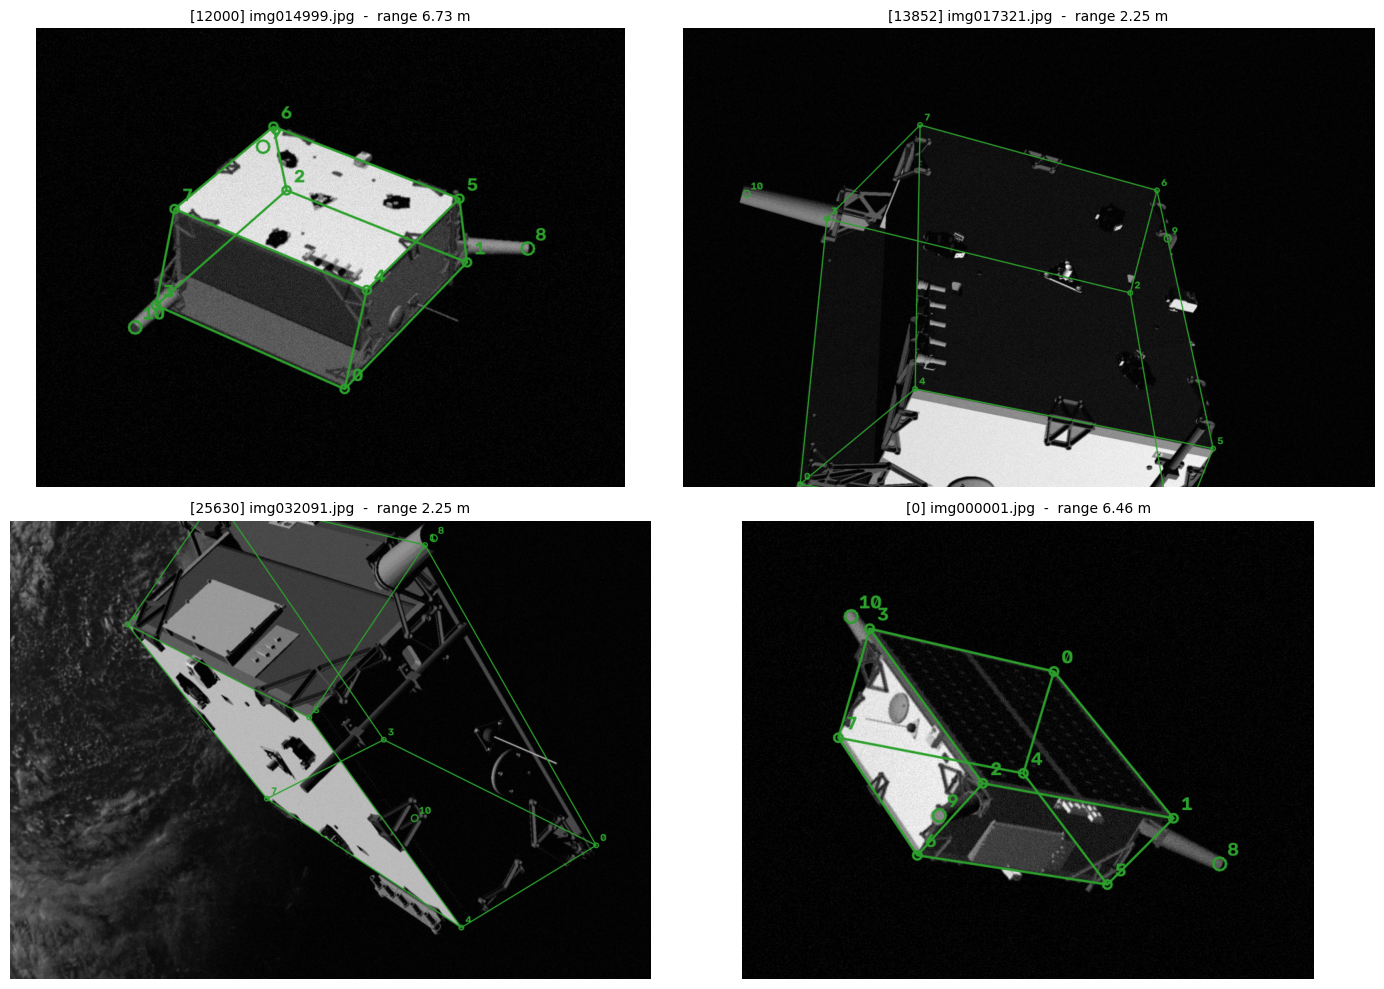

In [4]:
images, titles = [], []
for index in SAMPLE_INDICES:
    q, t = pose_of(index)
    projected = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
    canvas = draw_wireframe(load_image(index), projected, GREEN, label_points=True)
    images.append(crop_around(canvas, projected, margin_frac=0.25))
    titles.append(f"[{index}] {entries[index]['filename']}  -  range {np.linalg.norm(t):.2f} m")

show(images, titles)

## 2. Exact round trip

Project with the ground-truth pose, pass the exact pixels to `solve_pose`, and compare. The 0.051° rotation floor comes from the `eps` clamp in `geodesic_angle` (acos clamped at 1 - 1e-7), not from the solver.

In [5]:
indices = rng.choice(len(entries), N_STAT_SAMPLES, replace=False)

rot_errors, trans_errors, failures = [], [], 0
for index in indices:
    q, t = pose_of(int(index))
    projected = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
    result = solve_pose(projected, camera)
    if not result.success:
        failures += 1
        continue
    rot_errors.append(rotation_error_deg(result.quaternion, q))
    trans_errors.append(translation_error(result.translation, t))

rot_errors, trans_errors = np.array(rot_errors), np.array(trans_errors)
print(f"samples            {len(rot_errors)}")
print(f"PnP failures       {failures}")
print(f"rotation error     mean {rot_errors.mean():.4f} deg   max {rot_errors.max():.4f} deg")
print(f"translation error  mean {trans_errors.mean():.3e}     max {trans_errors.max():.3e}")

samples            300
PnP failures       0
rotation error     mean 0.0512 deg   max 0.0512 deg
translation error  mean 4.574e-09     max 2.416e-08


## 3. Sensitivity to keypoint noise

Gaussian noise of known std-dev is added to the exact keypoints before solving, which turns detector pixel error into expected pose error. Plotted as the median with an interquartile band, since the errors are skewed.

In [6]:
sweep_indices = indices[:80]
rot_by_noise, trans_by_noise, fail_by_noise = [], [], []

for noise in NOISE_LEVELS_PX:
    rot, trans, fails = [], [], 0
    for index in sweep_indices:
        q, t = pose_of(int(index))
        exact = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
        for _ in range(N_TRIALS):
            noisy = exact + rng.normal(0.0, noise, exact.shape) if noise else exact
            result = solve_pose(noisy, camera)
            if not result.success:
                fails += 1
                continue
            rot.append(rotation_error_deg(result.quaternion, q))
            trans.append(translation_error(result.translation, t))
    rot_by_noise.append(np.array(rot))
    trans_by_noise.append(np.array(trans))
    fail_by_noise.append(fails / (len(sweep_indices) * N_TRIALS))

for noise, rot, fails in zip(NOISE_LEVELS_PX, rot_by_noise, fail_by_noise):
    print(f"noise {noise:4.1f} px   median {np.median(rot):6.3f} deg   "
          f"p95 {np.percentile(rot, 95):7.3f} deg   failures {fails:.1%}")

noise  0.0 px   median  0.051 deg   p95   0.051 deg   failures 0.0%
noise  1.0 px   median  0.153 deg   p95   0.403 deg   failures 0.0%
noise  2.0 px   median  0.304 deg   p95   0.852 deg   failures 0.0%
noise  4.0 px   median  0.715 deg   p95   2.102 deg   failures 0.0%
noise  8.0 px   median  1.900 deg   p95   5.420 deg   failures 0.0%


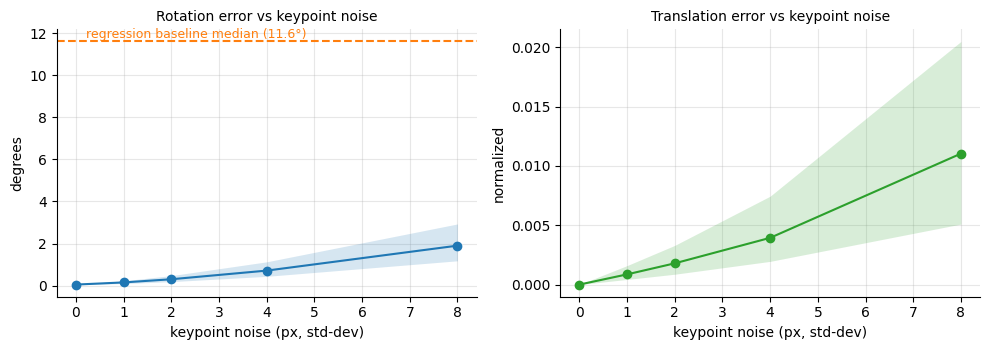

In [7]:
fig, (ax_rot, ax_trans) = plt.subplots(1, 2, figsize=(10, 3.6))

for ax, series, color, title, ylabel in [
    (ax_rot, rot_by_noise, BLUE, "Rotation error vs keypoint noise", "degrees"),
    (ax_trans, trans_by_noise, GREEN, "Translation error vs keypoint noise", "normalized"),
]:
    median = [np.median(s) for s in series]
    lo = [np.percentile(s, 25) for s in series]
    hi = [np.percentile(s, 75) for s in series]
    ax.fill_between(NOISE_LEVELS_PX, lo, hi, color=color, alpha=0.18, linewidth=0)
    ax.plot(NOISE_LEVELS_PX, median, color=color, marker="o")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("keypoint noise (px, std-dev)")
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)

ax_rot.axhline(BASELINE_ROT_MEDIAN_DEG, color=ORANGE, linewidth=1.5, linestyle="--")
ax_rot.text(0.2, BASELINE_ROT_MEDIAN_DEG, f"regression baseline median ({BASELINE_ROT_MEDIAN_DEG}°)",
            color=ORANGE, fontsize=9, va="bottom")

plt.tight_layout()
plt.show()

## 4. Annotated estimates

Solid green is the ground-truth pose and dashed orange is the pose PnP recovers. Both are the same 3D model drawn with different poses, so any gap between them is pose error. The first set shows one frame at 0, 2, 8 and 16 px of keypoint noise. The second shows four frames at 2 px.

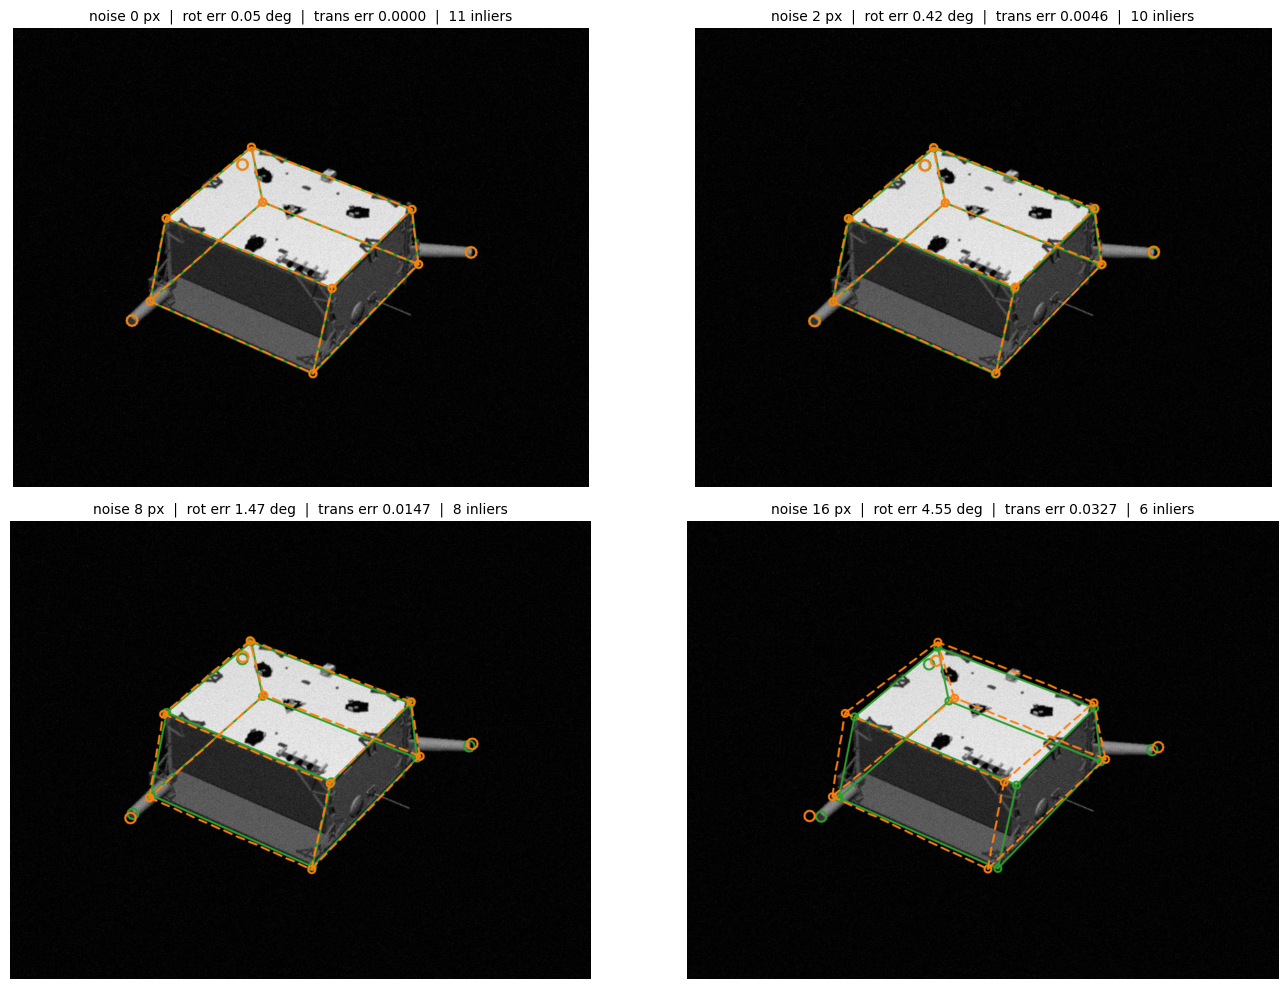

In [8]:
def annotate_estimate(index, noise_px, seed=0):
    """Draw GT vs PnP-recovered wireframes on one frame."""
    local_rng = np.random.default_rng(seed)
    q, t = pose_of(index)
    exact = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
    observed = exact + local_rng.normal(0.0, noise_px, exact.shape) if noise_px else exact

    result = solve_pose(observed, camera)
    canvas = draw_wireframe(load_image(index), exact, GREEN)
    extent = exact
    if result.success:
        recovered = project_points(TANGO_KEYPOINTS_BODY, result.quaternion, result.translation, camera)
        canvas = draw_wireframe(canvas, recovered, ORANGE, dashed=True)
        extent = np.vstack([exact, recovered])
        title = (f"noise {noise_px:.0f} px  |  rot err {rotation_error_deg(result.quaternion, q):.2f} deg  "
                 f"|  trans err {translation_error(result.translation, t):.4f}  |  {result.num_inliers} inliers")
    else:
        title = f"noise {noise_px:.0f} px  |  PnP FAILED"
    return crop_around(canvas, extent), title


index = SAMPLE_INDICES[0]
panels = [annotate_estimate(index, noise, seed=3) for noise in [0.0, 2.0, 8.0, 16.0]]
show([p[0] for p in panels], [p[1] for p in panels])

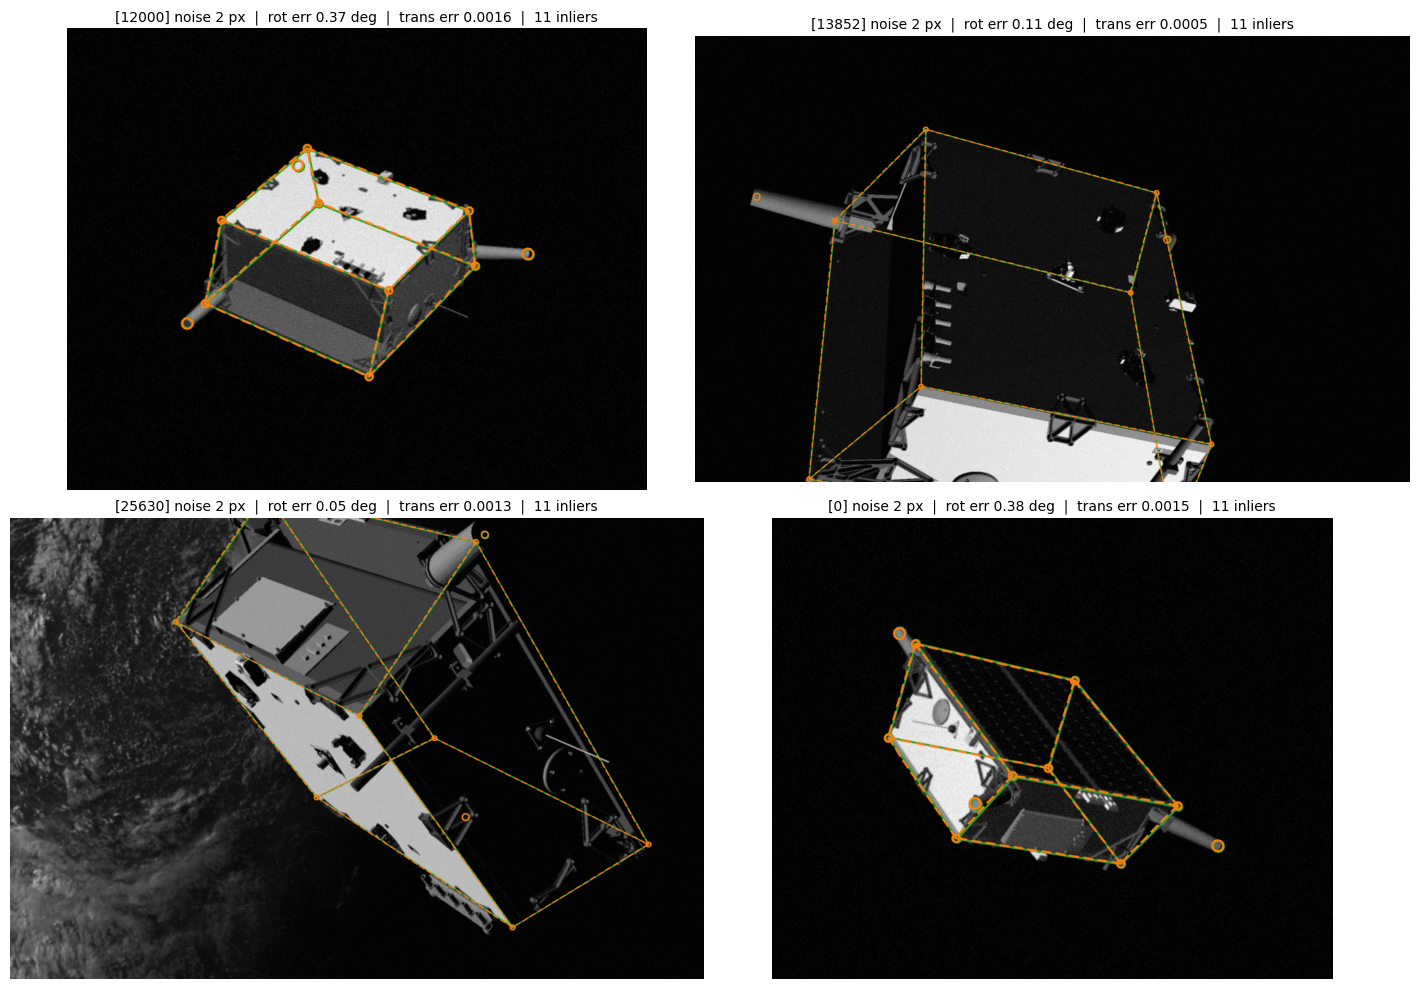

In [9]:
# four frames at 2 px noise
panels = [annotate_estimate(i, 2.0, seed=7) for i in SAMPLE_INDICES]
show([p[0] for p in panels],
     [f"[{i}] {t}" for i, (_, t) in zip(SAMPLE_INDICES, panels)])

## 5. Outlier rejection

Self-occluded keypoints have no visibility label, so a detector will sometimes place one confidently in the wrong spot. `solve_pose` uses `solvePnPRansac` to drop those. Here `k` keypoints are moved to random image locations, with 1 px noise on the rest.

In [10]:
corruptions = [0, 1, 2, 3, 4]
rot_by_corruption, inliers_by_corruption, fail_by_corruption = [], [], []

for k in corruptions:
    rot, inliers, fails = [], [], 0
    for index in sweep_indices[:40]:
        q, t = pose_of(int(index))
        exact = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
        for _ in range(N_TRIALS):
            observed = exact + rng.normal(0.0, 1.0, exact.shape)
            if k:
                victims = rng.choice(len(observed), k, replace=False)
                observed[victims] = rng.uniform([0, 0], [camera.width, camera.height], (k, 2))
            result = solve_pose(observed, camera)
            if not result.success:
                fails += 1
                continue
            rot.append(rotation_error_deg(result.quaternion, q))
            inliers.append(result.num_inliers)
    rot_by_corruption.append(np.array(rot))
    inliers_by_corruption.append(np.mean(inliers) if inliers else 0.0)
    fail_by_corruption.append(fails / (40 * N_TRIALS))
    print(f"{k} corrupted   median {np.median(rot):6.3f} deg   "
          f"p95 {np.percentile(rot, 95):8.3f} deg   mean inliers {inliers_by_corruption[-1]:4.1f}   "
          f"failures {fail_by_corruption[-1]:.1%}")

0 corrupted   median  0.148 deg   p95    0.406 deg   mean inliers 11.0   failures 0.0%
1 corrupted   median  0.153 deg   p95    0.398 deg   mean inliers 10.0   failures 0.0%


2 corrupted   median  0.161 deg   p95    0.422 deg   mean inliers  9.0   failures 0.0%


3 corrupted   median  0.188 deg   p95    0.512 deg   mean inliers  8.0   failures 0.0%


4 corrupted   median  0.207 deg   p95    0.566 deg   mean inliers  7.0   failures 0.6%


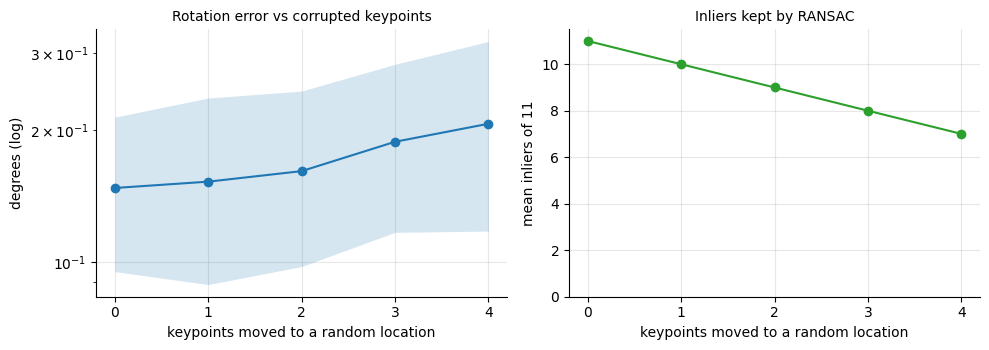

In [11]:
fig, (ax_err, ax_in) = plt.subplots(1, 2, figsize=(10, 3.6))

median = [np.median(s) for s in rot_by_corruption]
lo = [np.percentile(s, 25) for s in rot_by_corruption]
hi = [np.percentile(s, 75) for s in rot_by_corruption]
ax_err.fill_between(corruptions, lo, hi, color=BLUE, alpha=0.18, linewidth=0)
ax_err.plot(corruptions, median, color=BLUE, marker="o")
ax_err.set_yscale("log")
ax_err.set_title("Rotation error vs corrupted keypoints", fontsize=10)
ax_err.set_xlabel("keypoints moved to a random location")
ax_err.set_ylabel("degrees (log)")
ax_err.set_xticks(corruptions)
ax_err.set_axisbelow(True)

ax_in.plot(corruptions, inliers_by_corruption, color=GREEN, marker="o")
ax_in.set_title("Inliers kept by RANSAC", fontsize=10)
ax_in.set_xlabel("keypoints moved to a random location")
ax_in.set_ylabel("mean inliers of 11")
ax_in.set_xticks(corruptions)
ax_in.set_ylim(0, 11.5)
ax_in.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 6. Best case through the heatmap decoder

Sections 2-5 give PnP continuous pixel coordinates. The real pipeline goes through a stride-4 heatmap and `decode_heatmaps`, which quantizes the peak and then refines it. Running ground-truth heatmaps through that path gives the best score a perfect detector could reach.

Keypoint error counts visible keypoints only. Points that project outside the frame have an all-zero target heatmap, so their decoded location is meaningless. Their peak value is ~0, though, so the confidence filter in `solve_pose` drops them.

In [12]:
from torch.utils.data import DataLoader, Subset

from tumbleweed.data.speedplus import SpeedPlusDataset
from tumbleweed.data.transforms import build_keypoint_transforms
from tumbleweed.geometry.heatmaps import decode_heatmaps
from tumbleweed.metrics import distribution_stats, flip_rate, speed_score
from tumbleweed.train_keypoints import keypoint_pixel_error

transform = build_keypoint_transforms(camera)
oracle_set = Subset(SpeedPlusDataset(DATA_ROOT, "synthetic", "validation", transform=transform),
                    range(32))
batch = next(iter(DataLoader(oracle_set, batch_size=32)))

coords, confidence = decode_heatmaps(batch["heatmaps"])
to_full_res = np.array([4 * camera.width / 640, 4 * camera.height / 384])
keypoints_px = coords.numpy() * to_full_res

visible = batch["keypoint_visible"]
pixel_error = keypoint_pixel_error(coords, batch["keypoints_px"], visible, to_full_res)
off_frame = int((1 - visible).sum())

translations, quaternions, oracle_failures = [], [], 0
for kp, conf in zip(keypoints_px, confidence.numpy()):
    result = solve_pose(kp, camera, conf)
    oracle_failures += not result.success
    translations.append(result.translation)
    quaternions.append(result.quaternion)

scored = speed_score(
    torch.tensor(np.stack(translations)).float(), torch.tensor(np.stack(quaternions)).float(),
    batch["translation"], batch["quaternion"],
)
stats = {**distribution_stats("rotation_error_deg", scored["rotation_error_deg"]),
         "flip_rate_90deg": flip_rate(scored["rotation_error_deg"]),
         "mean_speed_score": scored["score"].mean().item()}

print(f"keypoint decode error   {pixel_error:.2f} px (visible only; stride-4 quantization)")
print(f"off-frame keypoints     {off_frame} of {visible.numel()} - dropped by the confidence filter")
print(f"PnP failures            {oracle_failures}")
print(f"mean rotation error     {stats['mean_rotation_error_deg']:.4f} deg")
print(f"p95 rotation error      {stats['p95_rotation_error_deg']:.4f} deg")
print(f"flip rate (>90 deg)     {stats['flip_rate_90deg']:.4f}")
print(f"mean SPEC score         {stats['mean_speed_score']:.5f}")
print(f"\nregression baseline     {BASELINE_ROT_MEAN_DEG} deg mean, SPEC {BASELINE_SPEC}")

keypoint decode error   1.22 px (visible only; stride-4 quantization)
off-frame keypoints     8 of 352 - dropped by the confidence filter
PnP failures            0
mean rotation error     0.1770 deg
p95 rotation error      0.3853 deg
flip rate (>90 deg)     0.0000
mean SPEC score         0.00423

regression baseline     17.9 deg mean, SPEC 0.354


## 7. Trained checkpoint

Same annotation as section 4, using the trained network. Blue dots are the detected keypoints, and dashed orange is the PnP pose from them. Skipped if no checkpoint exists.

First run (12 epochs; `best.pt` is from epoch 10): the detector finds the corners and antenna tips but swaps Tango's left/right mirror pairs (1/2, 5/6, 8/9) about half the time. Those swaps make the correspondences inconsistent, and PnP fails on roughly 90% of validation frames (`checkpoints/keypoint/metrics.csv`). Section 8 fixes most of this without retraining.

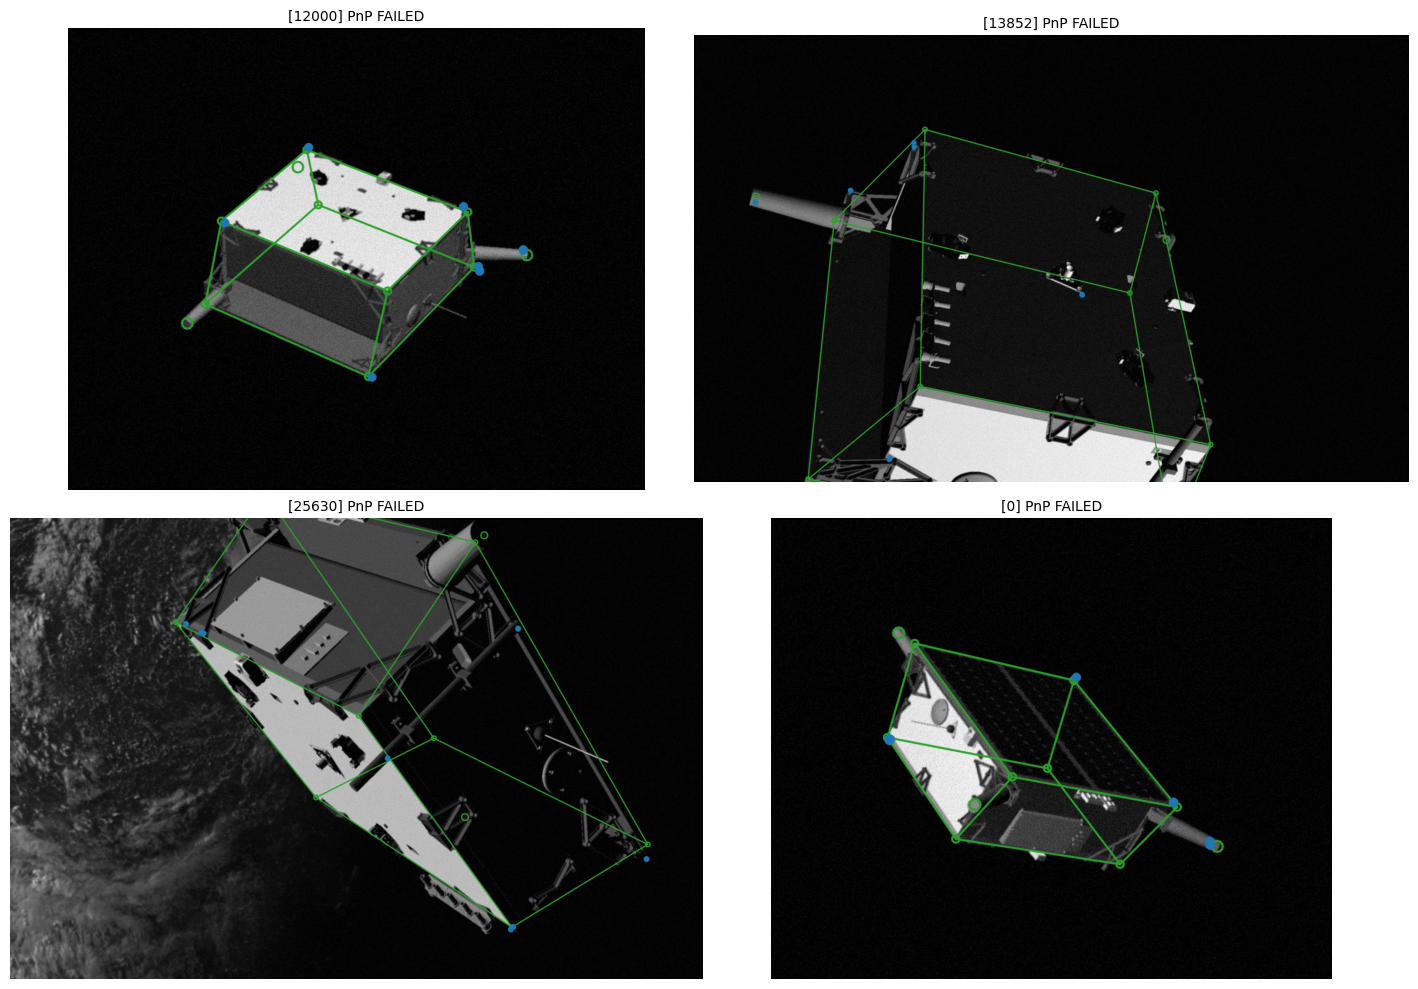

In [13]:
from tumbleweed.models.keypoint_resnet import KeypointPoseEstimator, KeypointResNet18

if not KEYPOINT_CHECKPOINT.exists():
    print(f"No checkpoint at {KEYPOINT_CHECKPOINT} - train one first, then re-run this cell.")
else:
    state = torch.load(KEYPOINT_CHECKPOINT, map_location="cpu")
    network = KeypointResNet18(pretrained=False)
    network.load_state_dict(state["model"] if "model" in state else state)
    network.eval()
    estimator = KeypointPoseEstimator(network, camera)

    dataset = SpeedPlusDataset(DATA_ROOT, DOMAIN, SPLIT, transform=transform)
    images, titles = [], []
    for index in SAMPLE_INDICES:
        sample = dataset[index]
        with torch.no_grad():
            heatmaps = network(sample["image"][None])
        coords, conf = decode_heatmaps(heatmaps)
        detected = coords[0].numpy() * to_full_res

        q, t = pose_of(index)
        result = solve_pose(detected, camera, conf[0].numpy())
        truth = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
        canvas = draw_wireframe(load_image(index), truth, GREEN)
        for u, v in detected:
            cv2.circle(canvas, (int(round(u)), int(round(v))), 7, to_bgr(BLUE), -1, cv2.LINE_AA)
        extent = np.vstack([truth, detected])
        if result.success:
            recovered = project_points(TANGO_KEYPOINTS_BODY, result.quaternion, result.translation, camera)
            canvas = draw_wireframe(canvas, recovered, ORANGE, dashed=True)
            extent = np.vstack([extent, recovered])
            titles.append(f"[{index}] rot err {rotation_error_deg(result.quaternion, q):.2f} deg  "
                          f"|  {result.num_inliers} inliers")
        else:
            titles.append(f"[{index}] PnP FAILED")
        images.append(crop_around(canvas, extent))

    show(images, titles)

## 8. Regression prior

The detector's mistakes are mostly identity swaps, not missing blobs. Where it can't tell corner 1 from corner 2, it puts a peak on both. The regression model is too coarse to use directly (11.6° median) but rarely confuses left and right, so it can pick between the two. For each frame:

1. Run the regression model for a rough pose and project the 11 model points with it.
2. Take the 4 strongest peaks in each heatmap (`find_peaks`) and keep the one nearest each projected point (`select_by_prior`).
3. Solve PnP with a 20 px RANSAC threshold. If the solve fails, or lands far from the prior (see the gate below), the frame keeps the regression pose.

Nothing is retrained. Results are `tumbleweed.eval --advanced` on all 11,994 synthetic/validation frames, one CSV per run in `results/`. `keypoint_prior_val.csv` was written before the gate existed, and `keypoint_prior_gated_val.csv` comes from the command at the top of the notebook.

In [14]:
import pandas as pd

RUNS = {
    "regression": "regression_val.csv",
    "keypoint": "keypoint_val.csv",
    "keypoint + prior": "keypoint_prior_val.csv",
    "keypoint + prior, gated": "keypoint_prior_gated_val.csv",
}
T_GT = ["t_gt_x", "t_gt_y", "t_gt_z"]
T_PRED = ["t_pred_x", "t_pred_y", "t_pred_z"]
Q_PRED = ["q_pred_w", "q_pred_x", "q_pred_y", "q_pred_z"]

runs = {}
for name, filename in RUNS.items():
    path = RESULTS_DIR / filename
    if path.exists():
        runs[name] = pd.read_csv(path)
    else:
        print(f"missing results/{filename}, so '{name}' is left out")


def summarize(frame):
    rot = frame["rotation_error_deg"]
    trans_m = np.linalg.norm(frame[T_PRED].values - frame[T_GT].values, axis=1)
    return {
        "rot median (deg)": rot.median(),
        "rot p90": rot.quantile(0.9),
        "rot p95": rot.quantile(0.95),
        "flips >90° (%)": 100 * (rot > 90).mean(),
        "trans median (cm)": 100 * np.median(trans_m),
        "trans mean (norm.)": frame["translation_error"].mean(),
        "SPEC": frame["speed_score"].mean(),
    }


pd.DataFrame({name: summarize(frame) for name, frame in runs.items()}).T.round(3)

,rot median (deg),rot p90,rot p95,flips >90° (%),trans median (cm),trans mean (norm.),SPEC
regression,11.603,32.359,53.608,2.493,18.579,0.042,0.354
keypoint,127.402,170.616,175.329,75.121,540.067,3.833,5.857
keypoint + prior,5.302,31.938,60.800,3.160,11.817,0.361,0.613
"keypoint + prior, gated",5.347,31.139,53.591,2.593,11.725,0.035,0.276


### Rotation

With the prior, the median rotation error halves, from 11.6° to 5.3°. The tail barely moves. When the regression pose is badly wrong, it steers the selection to the wrong peaks, and PnP recovers that wrong pose precisely, so p90 stays near 32°. The plain keypoint run is left off the plot. Its PnP fails on ~90% of frames and returns the identity placeholder.

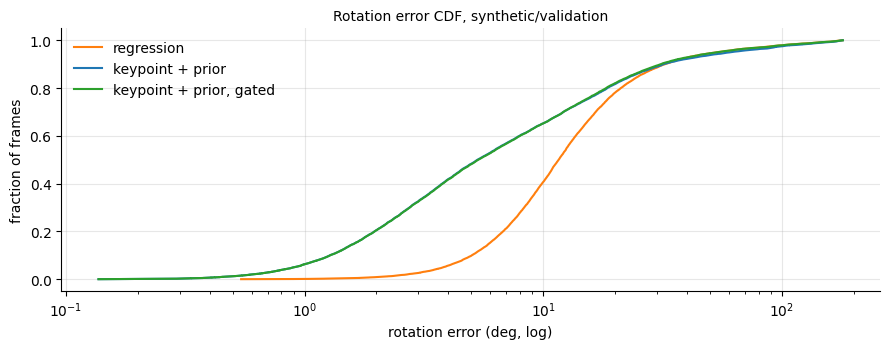

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for name, color in [("regression", ORANGE), ("keypoint + prior", BLUE), ("keypoint + prior, gated", GREEN)]:
    if name in runs:
        rot = np.sort(runs[name]["rotation_error_deg"].values)
        ax.plot(rot, np.arange(1, len(rot) + 1) / len(rot), color=color, label=name)
ax.set_xscale("log")
ax.set_xlabel("rotation error (deg, log)")
ax.set_ylabel("fraction of frames")
ax.set_title("Rotation error CDF, synthetic/validation", fontsize=10)
ax.legend(frameon=False)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Translation outliers

Without the gate, the mean SPEC score (0.613) is worse than regression's (0.354), even though median rotation and median translation both improved. A few solves passed RANSAC with a nonsense pose. With a 20 px threshold, 4-5 badly placed points can agree on a tiny spacecraft far from the camera. The worst one puts Tango 6.4 km away when it is 3.1 m away. SPEC is a mean, so the 10 frames with translation error above 10x the range are enough to dominate it.

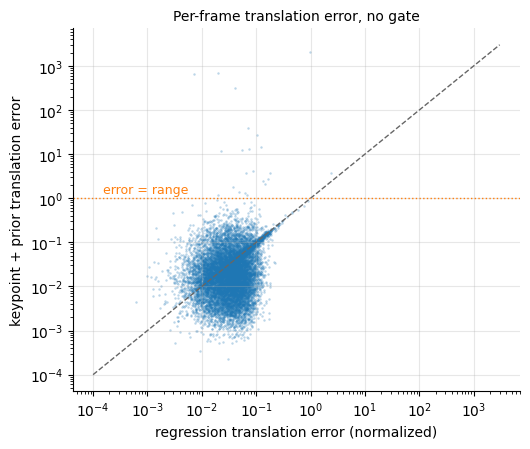

translation error >  0.5: keypoint + prior  48 frames, regression   5
translation error >    1: keypoint + prior  22 frames, regression   1
translation error >   10: keypoint + prior  10 frames, regression   0


,filename,true range (m),predicted range (m),rotation error (deg)
11716,img058602.jpg,3.14,6355.99,65.73
5359,img026883.jpg,2.46,1723.11,80.86
8628,img043230.jpg,5.98,3956.68,71.97
7922,img039862.jpg,2.70,868.44,118.42
10517,img052594.jpg,7.73,313.55,56.72


In [16]:
reg, prior = runs["regression"], runs["keypoint + prior"]
assert (reg["filename"].values == prior["filename"].values).all()

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.scatter(reg["translation_error"], prior["translation_error"], s=3, alpha=0.3, color=BLUE, linewidths=0)
ax.plot([1e-4, 3e3], [1e-4, 3e3], color="0.4", linewidth=1, linestyle="--")
ax.axhline(1.0, color=ORANGE, linewidth=1, linestyle=":")
ax.text(1.5e-4, 1.3, "error = range", color=ORANGE, fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("regression translation error (normalized)")
ax.set_ylabel("keypoint + prior translation error")
ax.set_title("Per-frame translation error, no gate", fontsize=10)
plt.tight_layout()
plt.show()

for threshold in [0.5, 1, 10]:
    print(f"translation error > {threshold:>4}: keypoint + prior {(prior['translation_error'] > threshold).sum():3d} frames, "
          f"regression {(reg['translation_error'] > threshold).sum():3d}")

worst = prior.nlargest(5, "translation_error")
pd.DataFrame({
    "filename": worst["filename"],
    "true range (m)": worst["gt_range_m"],
    "predicted range (m)": np.linalg.norm(worst[T_PRED].values, axis=1),
    "rotation error (deg)": worst["rotation_error_deg"],
}).round(2)

### Gate

A PnP result is now treated as a failure if its translation is more than 25% of the range away from the prior's, or its rotation more than 45° away (`max_translation_deviation` and `max_rotation_deviation_deg` in `KeypointPoseEstimator`). Such frames fall back to the prior, the same as a failed solve.

The thresholds come from replaying the ungated run. For each frame, swap in the regression result wherever the two disagree by more than the gate. This approximates the real gate rather than reproducing it exactly. The regression run resizes the full frame to 224x224, while the prior inside the estimator resizes the 384x640 input, so their poses differ slightly. Rejecting only the gross disagreements already brings SPEC below the regression baseline without moving the median.

In [17]:
t_dev = np.linalg.norm(prior[T_PRED].values - reg[T_PRED].values, axis=1) / np.linalg.norm(reg[T_PRED].values, axis=1)
r_dev = np.rad2deg(geodesic_angle(torch.tensor(prior[Q_PRED].values), torch.tensor(reg[Q_PRED].values)).numpy())

rows = {}
for t_max, r_max in [(np.inf, np.inf), (0.5, np.inf), (0.25, np.inf), (0.25, 45), (0.25, 30)]:
    rejected = (t_dev > t_max) | (r_dev > r_max)
    t_err = np.where(rejected, reg["translation_error"], prior["translation_error"])
    r_err = np.where(rejected, reg["rotation_error_deg"], prior["rotation_error_deg"])
    label = "no gate" if np.isinf(t_max) else f"t > {t_max:.0%}" + ("" if np.isinf(r_max) else f" or r > {r_max}°")
    rows[label] = {
        "frames replaced": int(rejected.sum()),
        "rot median (deg)": np.median(r_err),
        "rot p95": np.percentile(r_err, 95),
        "trans mean (norm.)": t_err.mean(),
        "SPEC": (t_err + np.deg2rad(r_err)).mean(),
    }

print(f"regression alone: SPEC {reg['speed_score'].mean():.3f}")
pd.DataFrame(rows).T.round(3)

regression alone: SPEC 0.354


,frames replaced,rot median (deg),rot p95,trans mean (norm.),SPEC
no gate,0.0,5.302,60.800,0.361,0.613
t > 50%,39.0,5.297,60.203,0.039,0.290
t > 25%,162.0,5.297,58.612,0.036,0.285
t > 25% or r > 45°,578.0,5.379,55.606,0.035,0.278
t > 25% or r > 30°,1159.0,5.591,53.923,0.034,0.281


### Annotated frames

Four validation frames: a typical one, a large improvement, one where the prior itself is wrong, and the 1,700 m outlier from the table above. Solid green is the ground truth, dashed gray the regression prior, blue dots the peaks `select_by_prior` kept, and dashed orange the final pose. The final pose comes from `KeypointPoseEstimator` with its default gate. The prior and the selected peaks are recomputed step by step so they can be drawn.

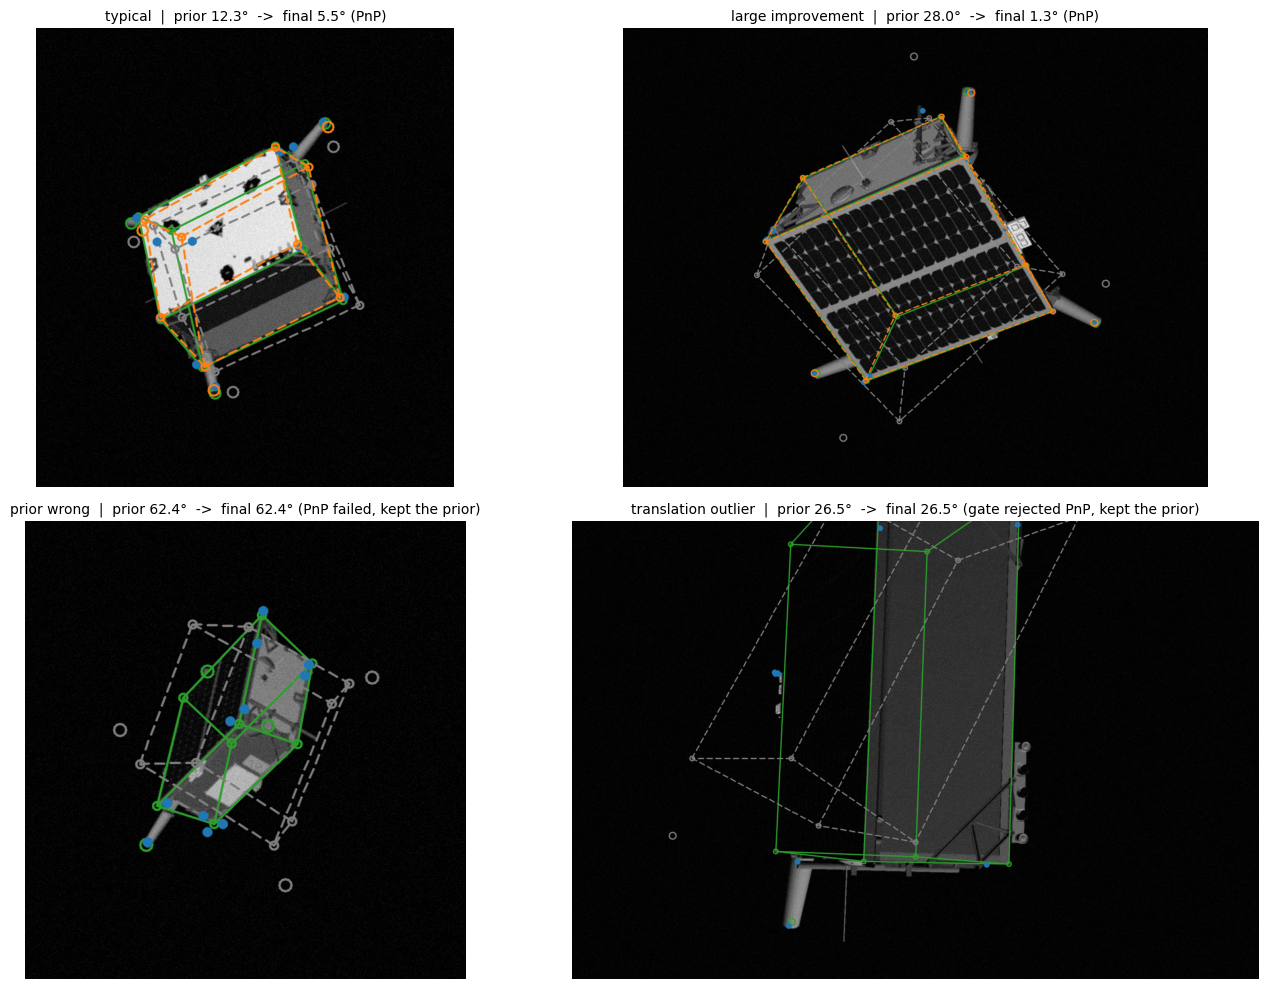

In [18]:
import torch.nn.functional as F

from tumbleweed.geometry.heatmaps import find_peaks
from tumbleweed.geometry.pnp import select_by_prior
from tumbleweed.models.pose_resnet import PoseResNet18

EXAMPLE_FRAMES = {
    "img000152.jpg": "typical",
    "img000301.jpg": "large improvement",
    "img000286.jpg": "prior wrong",
    "img026883.jpg": "translation outlier",
}
GRAY = "tab:gray"

if not (KEYPOINT_CHECKPOINT.exists() and REGRESSION_CHECKPOINT.exists()):
    print("Needs checkpoints/keypoint/best.pt and checkpoints/best.pt.")
else:
    state = torch.load(REGRESSION_CHECKPOINT, map_location="cpu")
    prior_model = PoseResNet18(pretrained=False)
    prior_model.load_state_dict(state["model"] if "model" in state else state)
    estimator = KeypointPoseEstimator(network, camera, prior_model=prior_model).eval()

    val_entries = json.load(open(DATA_ROOT / "synthetic" / "validation.json"))
    val_index = {entry["filename"]: i for i, entry in enumerate(val_entries)}
    val_set = SpeedPlusDataset(DATA_ROOT, "synthetic", "validation", transform=transform)

    images, titles = [], []
    for filename, label in EXAMPLE_FRAMES.items():
        index = val_index[filename]
        entry = val_entries[index]
        q = np.asarray(entry["q_vbs2tango_true"], dtype=np.float64)
        t = np.asarray(entry["r_Vo2To_vbs_true"], dtype=np.float64)
        image = val_set[index]["image"][None]

        estimator.reset_failure_stats()
        with torch.no_grad():
            final_t, final_q = (x[0].numpy().astype(np.float64) for x in estimator(image))
            small = F.interpolate(image, size=estimator.prior_image_size, mode="bilinear",
                                  align_corners=False, antialias=True)
            prior_t, prior_q = (x[0].numpy().astype(np.float64) for x in prior_model(small))
            coords, values = find_peaks(network(image), k=estimator.num_candidates)
        chosen, _ = select_by_prior(coords[0].numpy() * estimator.to_full_res, values[0].numpy(),
                                    prior_q, prior_t, camera)

        truth = project_points(TANGO_KEYPOINTS_BODY, q, t, camera)
        prior_px = project_points(TANGO_KEYPOINTS_BODY, prior_q, prior_t, camera)
        canvas = cv2.imread(str(DATA_ROOT / "synthetic" / "images" / filename))
        canvas = draw_wireframe(canvas, truth, GREEN)
        canvas = draw_wireframe(canvas, prior_px, GRAY, dashed=True)
        for u, v in chosen:
            cv2.circle(canvas, (int(round(u)), int(round(v))), 7, to_bgr(BLUE), -1, cv2.LINE_AA)

        used_prior = estimator.num_failures or estimator.num_rejected
        if not used_prior:
            final_px = project_points(TANGO_KEYPOINTS_BODY, final_q, final_t, camera)
            canvas = draw_wireframe(canvas, final_px, ORANGE, dashed=True)
        if estimator.num_failures:
            outcome = "PnP failed, kept the prior"
        elif estimator.num_rejected:
            outcome = "gate rejected PnP, kept the prior"
        else:
            outcome = "PnP"
        titles.append(f"{label}  |  prior {rotation_error_deg(prior_q, q):.1f}°  ->  "
                      f"final {rotation_error_deg(final_q, q):.1f}° ({outcome})")
        images.append(crop_around(canvas, np.vstack([truth, prior_px])))

    show(images, titles)